# První analýza dat – Ophir Vega PD300-IR (`data_correctedTimeStamp`)

Notebook načítá data s opravenou časovou osou (15 Hz, $\Delta t = 1/15\text{ s}$) z adresáře `data_correctedTimeStamp/`:
1. **Analýza jednotlivých souborů** – výpočet absolutního rozdílu dvou po sobě jdoucích hodnot $|\Delta y_i| = |y_{i+1} - y_i|$ a jednoduché numerické derivace $|\Delta y_i / \Delta t|$ (interaktivní prohlížení po jednotlivých teplotách + souhrnná tabulka).
2. **Porovnání všech 49 souborů v jednom grafu** – barevné rozlišení podle teploty (0 °C – 48 °C, střed 24 °C).

In [3]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Najdi adresář data_correctedTimeStamp (funguje při spuštění z notebooks/ i z kořene projektu)
DATA_DIR = Path("..") / "data_correctedTimeStamp"
if not DATA_DIR.is_dir():
    DATA_DIR = Path("data_correctedTimeStamp")
assert DATA_DIR.is_dir(), f"Adresář nenalezen: {DATA_DIR.resolve()}"


def extract_temp(path: Path) -> int:
    m = re.search(r"(-?\d+)", path.stem)
    return int(m.group(1)) if m else 9999


def load_starlab_file(path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Načte sloupce Timestamp [s] a Channel A [W] z opraveného StarLab souboru."""
    t_vals, y_vals = [], []
    in_data = False
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            if not in_data:
                if "Timestamp" in line and "Channel A" in line:
                    in_data = True
                continue
            parts = line.strip().split()
            if len(parts) >= 2:
                t_vals.append(float(parts[0]))
                y_vals.append(float(parts[1]))
    return np.asarray(t_vals, dtype=np.float64), np.asarray(y_vals, dtype=np.float64)


# Načtení všech souborů seřazených numericky podle teploty
files = sorted(DATA_DIR.glob("*.txt"), key=extract_temp)
datasets = {}

for p in files:
    temp = extract_temp(p)
    t, y = load_starlab_file(p)
    dt = np.diff(t)
    dy_abs = np.abs(np.diff(y))          # |y[i+1] - y[i]|  [W]
    dydt_abs = dy_abs / dt               # |dy / dt|        [W/s]
    datasets[temp] = {
        "name": p.name,
        "t": t,
        "y": y,
        "t_diff": t[1:],                 # čas odpovídající rozdílu y[i+1] - y[i]
        "dy_abs": dy_abs,
        "dydt_abs": dydt_abs,
    }

temps = sorted(datasets.keys())
print(f"Načteno {len(datasets)} souborů z: {DATA_DIR.resolve()}")
print(f"Teploty: {temps[0]} °C až {temps[-1]} °C, dt = {np.median(np.diff(datasets[temps[0]]['t'])):.6f} s")

Načteno 49 souborů z: D:\prog\python\jupyter\icaros48\data_correctedTimeStamp
Teploty: 0 °C až 48 °C, dt = 0.066667 s


## 1. Jednotlivé soubory: $|\Delta y|$ a jednoduchá derivace $|\Delta y / \Delta t|$

Nejprve rychlá souhrnná tabulka pro všechny soubory a poté vykreslení vybraného souboru (lze měnit interaktivně pomocí výběru teploty).

In [4]:
rows = []
for temp in temps:
    d = datasets[temp]
    idx_max = int(np.argmax(d["dy_abs"]))
    rows.append({
        "Teplota [°C]": temp,
        "Soubor": d["name"],
        "Vzorků": len(d["t"]),
        "y_min [µW]": d["y"].min() * 1e6,
        "y_max [µW]": d["y"].max() * 1e6,
        "max |Δy| [µW]": d["dy_abs"][idx_max] * 1e6,
        "max |Δy/Δt| [µW/s]": d["dydt_abs"][idx_max] * 1e6,
        "t(max |Δy|) [s]": d["t_diff"][idx_max],
    })

summary_df = pd.DataFrame(rows)
summary_df.head(10)

,Teplota [°C],Soubor,Vzorků,y_min [µW],y_max [µW],max |Δy| [µW],max |Δy/Δt| [µW/s],t(max |Δy|) [s]
0,0,0 C.txt,13504,0.7,68.7,1.8,26.999865,143.266667
1,1,1 C.txt,13503,1.2,57.1,2.0,29.999850,260.600000
2,2,2 C.txt,13504,1.6,67.1,0.8,12.000120,140.533333
3,3,3 C.txt,13504,1.0,57.1,0.9,13.499933,145.066667
4,4,4 C.txt,13504,0.9,56.6,0.3,4.499978,167.066667
5,5,5 C.txt,13503,1.3,56.0,0.4,5.999970,143.666667
6,6,6 C.txt,13503,1.1,55.4,0.1,1.499993,0.066667
7,7,7 C.txt,13504,1.4,56.7,0.3,4.500045,140.733333
8,8,8 C.txt,13503,1.2,67.6,0.5,7.500075,153.333333
9,9,9 C.txt,13504,1.1,55.7,0.3,4.500045,154.733333


In [5]:
def plot_single_temperature(temp: int, t_min: float = 0.0, t_max: float = 900.0) -> None:
    d = datasets[temp]
    mask_y = (d["t"] >= t_min) & (d["t"] <= t_max)
    mask_d = (d["t_diff"] >= t_min) & (d["t_diff"] <= t_max)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)

    # Horní graf: původní signál
    ax1.plot(d["t"][mask_y], d["y"][mask_y] * 1e6, color="tab:blue", lw=1.0)
    ax1.set_ylabel("Výkon Channel A [µW]")
    ax1.set_title(f"Soubor: {d['name']} ({temp} °C) – signál a absolutní rozdíl / derivace")

    # Dolní graf: |Δy| [µW] + sekundární osa pro |Δy/Δt| [µW/s]
    ax2.plot(d["t_diff"][mask_d], d["dy_abs"][mask_d] * 1e6, color="tab:red", lw=0.9)
    ax2.set_xlabel("Čas t [s]")
    ax2.set_ylabel("|Δy| [µW]", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

    ax2_r = ax2.twinx()
    y1, y2 = ax2.get_ylim()
    ax2_r.set_ylim(y1 * 15.0, y2 * 15.0)
    ax2_r.set_ylabel("|Δy / Δt| [µW/s]  (fs = 15 Hz)", color="darkred")
    ax2_r.tick_params(axis="y", labelcolor="darkred")
    ax2_r.grid(False)

    plt.tight_layout()
    plt.show()


# Interaktivní výběr teploty a časového okna (při běžícím Jupyteru)
try:
    import ipywidgets as widgets
    from IPython.display import display

    w_temp = widgets.IntSlider(value=12, min=temps[0], max=temps[-1], step=1, description="Teplota °C:")
    w_range = widgets.FloatRangeSlider(
        value=[0.0, 900.0], min=0.0, max=900.0, step=10.0, description="Čas [s]:", layout=widgets.Layout(width="500px")
    )
    out = widgets.interactive_output(
        lambda temp, tr: plot_single_temperature(temp, tr[0], tr[1]),
        {"temp": w_temp, "tr": w_range},
    )
    display(widgets.VBox([w_temp, w_range, out]))
except Exception:
    plot_single_temperature(12)

## 2. Všechny soubory v jednom grafu (0 °C – 48 °C)

Barevná škála `coolwarm` zvýrazňuje teplotu vůči referenčním **24 °C** (modrá = nižší teploty, červená = vyšší teploty).
- **Graf 2A:** Absolutní rozdíl $|\Delta y(t)|$ (a pravá osa $|\Delta y / \Delta t|$) pro všech 49 souborů v celém čase 0–900 s.
- **Graf 2B:** Detail oblasti nástupu a kmitání (100–350 s) pro lepší čitelnost dynamiky.
- **Graf 2C:** Pro srovnání všechny původní průběhy signálu `Channel A` $y(t)$ v jednom grafu.

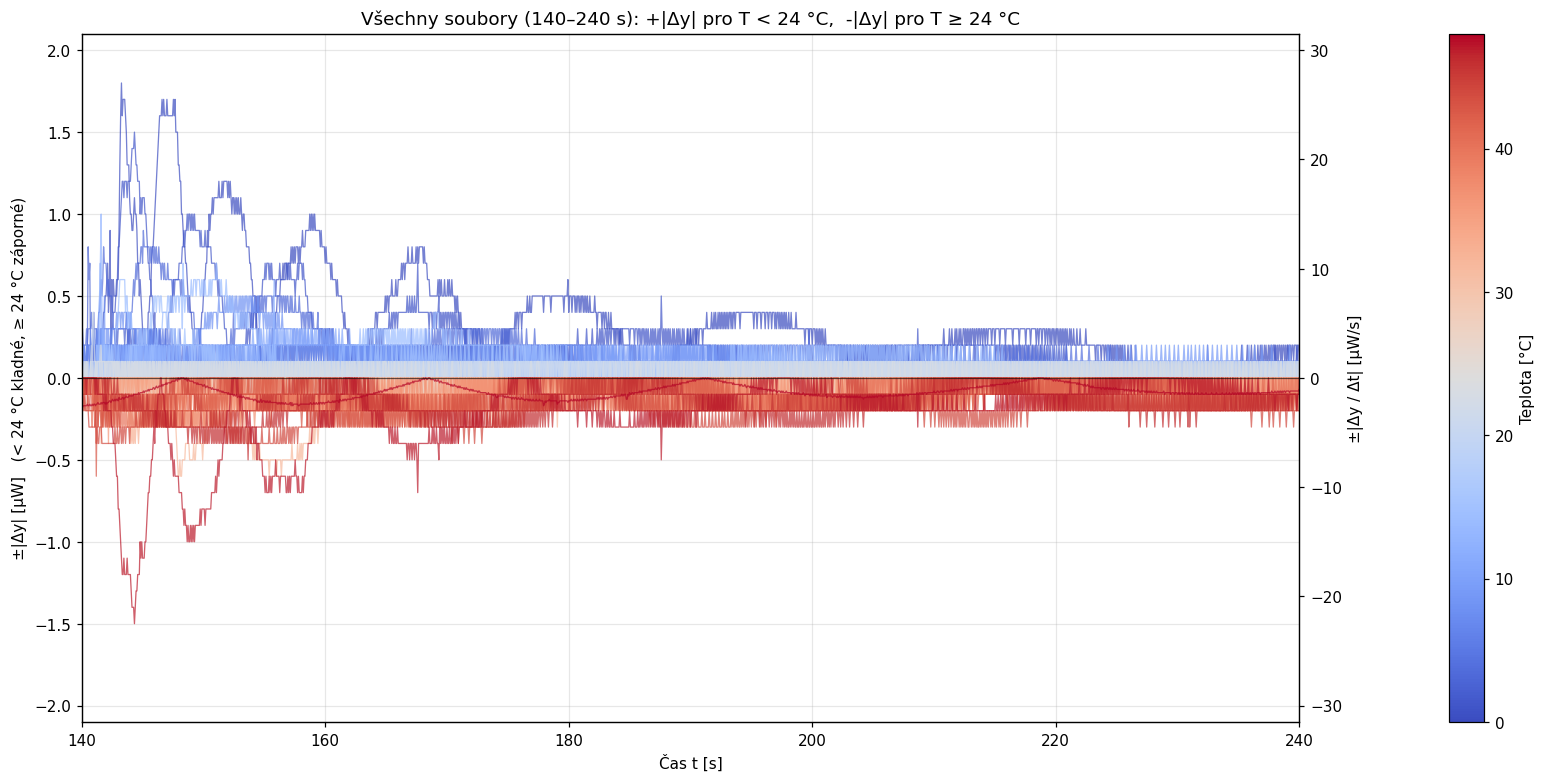

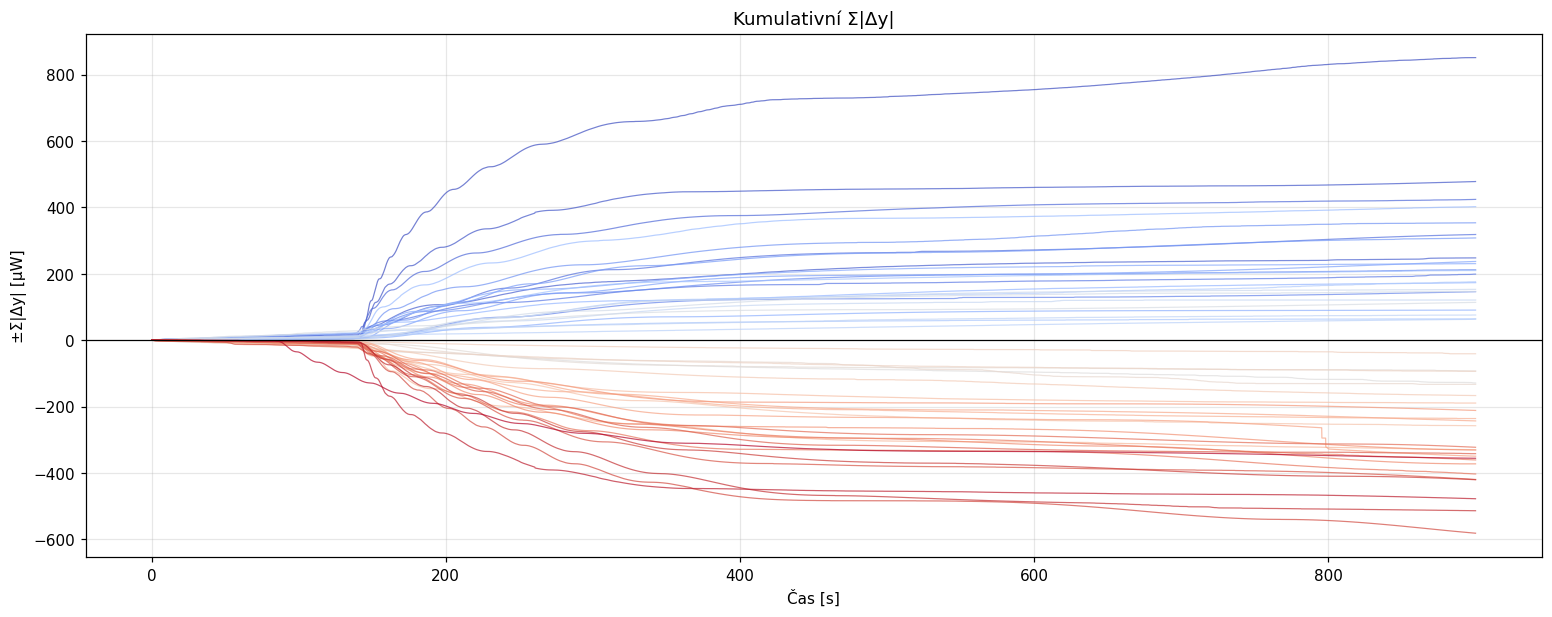

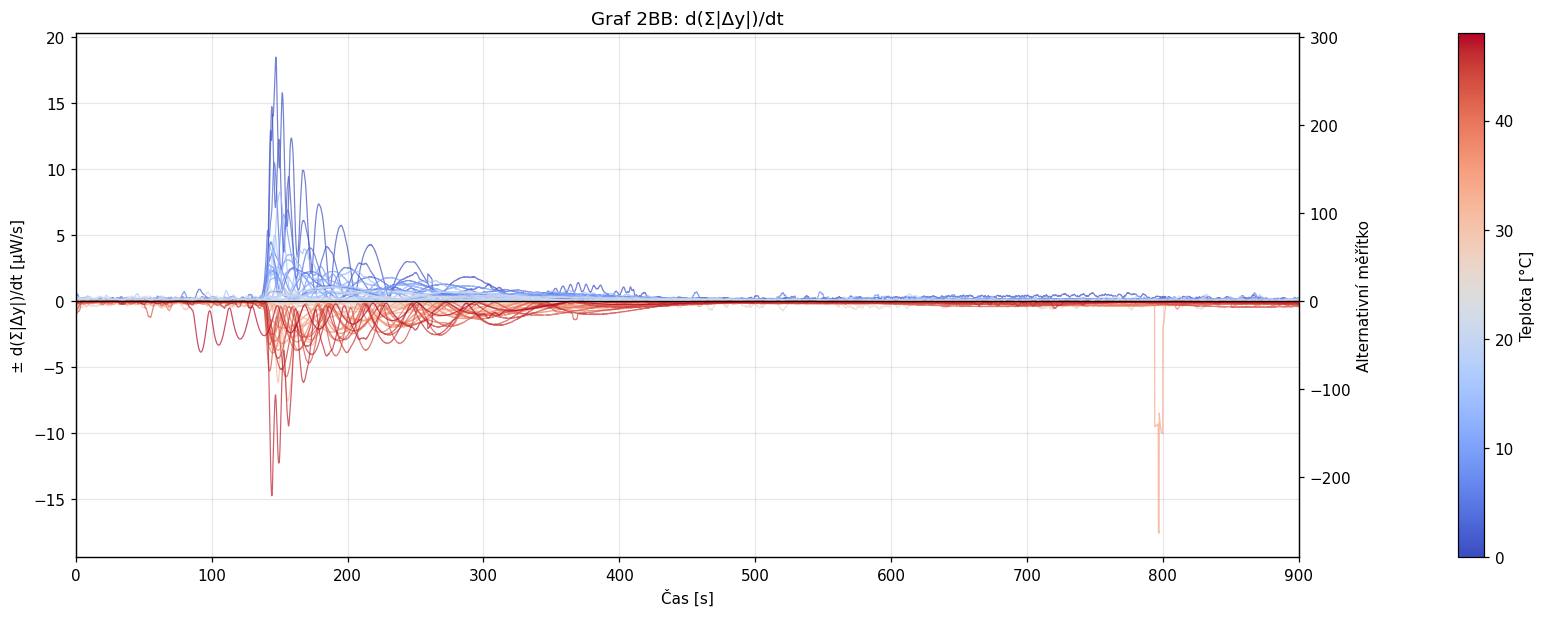

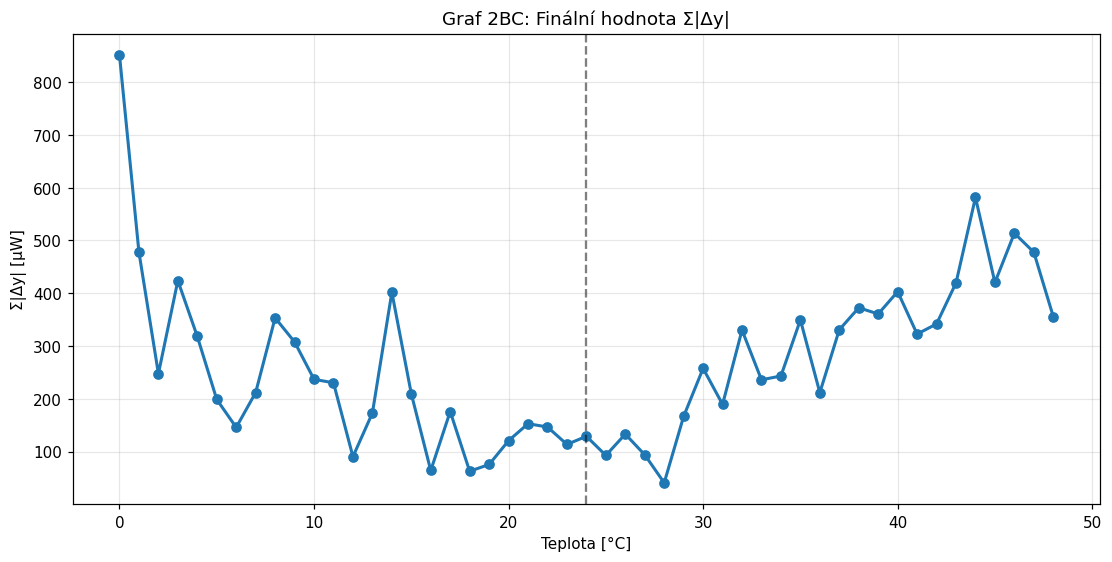

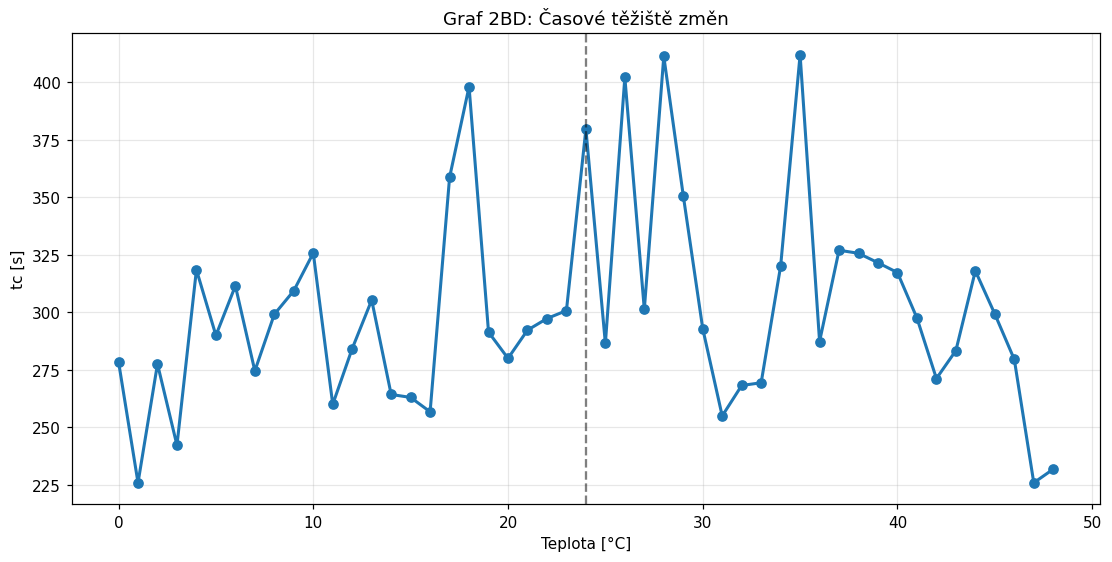

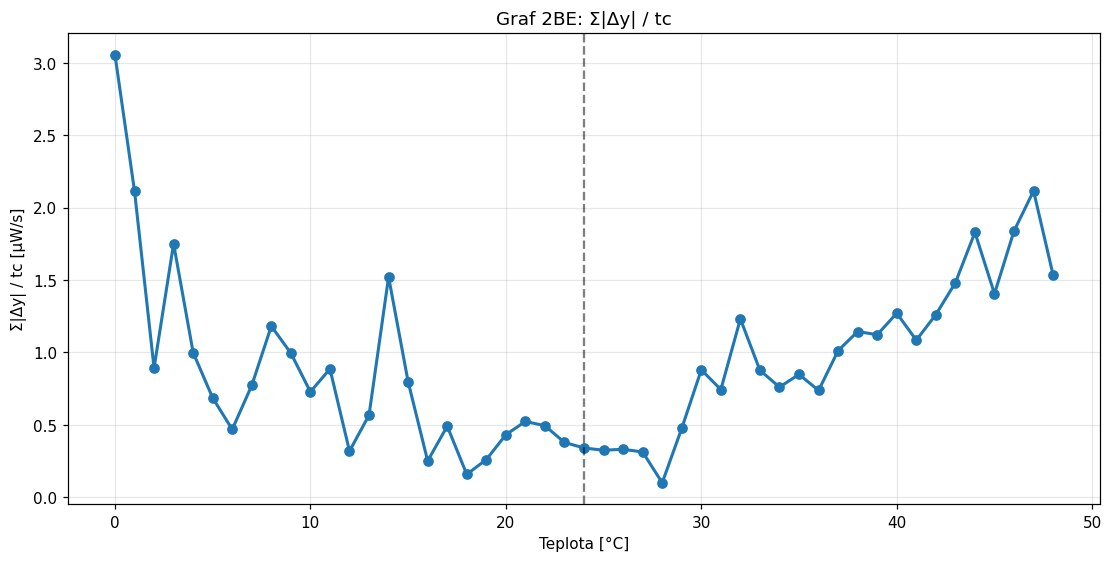

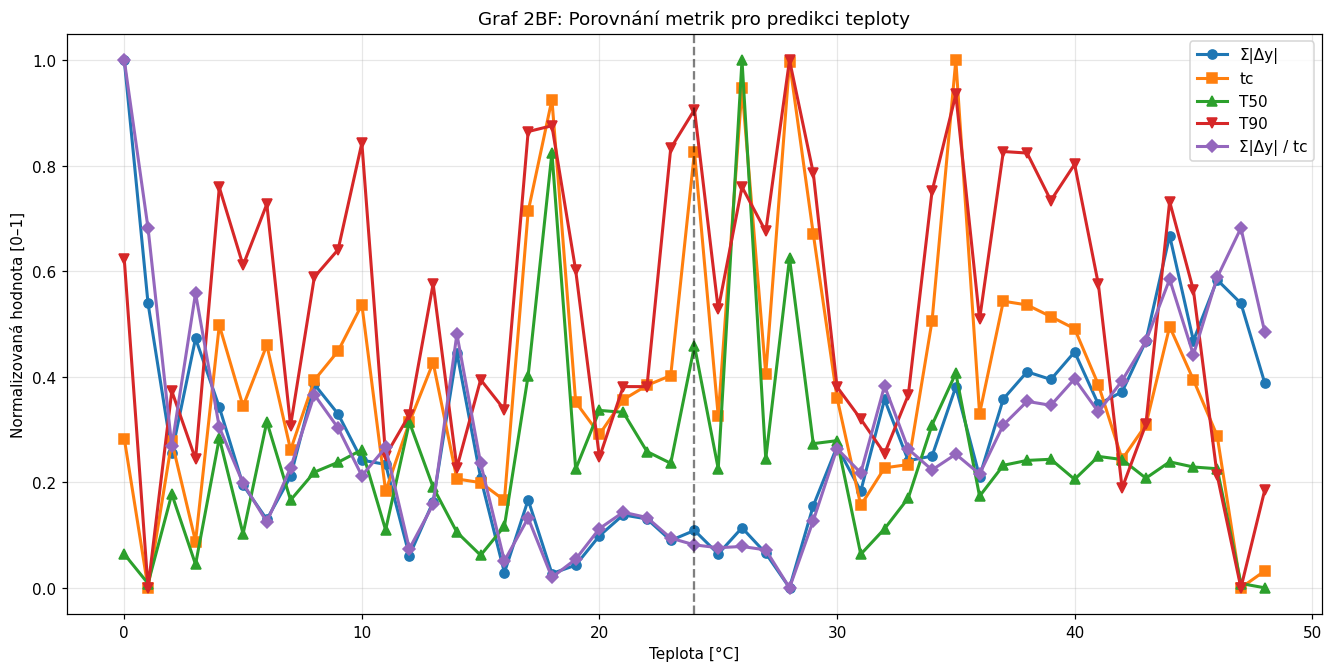

In [21]:
norm = mcolors.TwoSlopeNorm(vmin=min(temps), vcenter=24, vmax=max(temps))
cmap = cm.coolwarm
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Nastavení rozsahu os (lze snadno upravit)
T_MIN, T_MAX = 140, 240   # časové okno [s]
Y_MAX_UW = 2.1            # rozsah osy Y: [-Y_MAX_UW, +Y_MAX_UW] µW

# --- Graf 2A: Všechny průběhy ±|Δy(t)| v okně 140–240 s (< 24 °C kladné, >= 24 °C záporné) ---
fig, ax = plt.subplots(figsize=(14, 7.0), constrained_layout=True)
for temp in temps:
    d = datasets[temp]
    sign = -1.0 if temp >= 24 else 1.0
    mask = (d["t_diff"] >= T_MIN) & (d["t_diff"] <= T_MAX)
    ax.plot(d["t_diff"][mask], sign * d["dy_abs"][mask] * 1e6, color=cmap(norm(temp)), lw=0.85, alpha=0.7)

ax.axhline(0, color="black", lw=0.8, alpha=0.6)
ax.set_title(f"Všechny soubory ({T_MIN}–{T_MAX} s): +|Δy| pro T < 24 °C,  -|Δy| pro T ≥ 24 °C")
ax.set_xlabel("Čas t [s]")
ax.set_ylabel("±|Δy| [µW]   (< 24 °C kladné, ≥ 24 °C záporné)")
ax.set_xlim(T_MIN, T_MAX)
ax.set_ylim(-Y_MAX_UW, Y_MAX_UW)

ax_r = ax.twinx()
y1, y2 = ax.get_ylim()
ax_r.set_ylim(y1 * 15.0, y2 * 15.0)
ax_r.set_ylabel("±|Δy / Δt| [µW/s]")
ax_r.grid(False)

cbar = fig.colorbar(sm, ax=ax_r, pad=0.07)
cbar.set_label("Teplota [°C]")
plt.show()

# --- Graf 2B: Celý průběh 0–900 s (pro kontext) ---
fig, ax = plt.subplots(figsize=(14, 5.5), constrained_layout=True)

for temp in temps:
    d = datasets[temp]

    sign = -1 if temp >= 24 else 1

    cumulative = np.cumsum(d["dy_abs"])

    ax.plot(
        d["t_diff"],
        sign * cumulative * 1e6,
        color=cmap(norm(temp)),
        lw=0.8,
        alpha=0.7
    )

ax.axhline(0, color="black", lw=0.8)

ax.set_title("Kumulativní Σ|Δy|")
ax.set_xlabel("Čas [s]")
ax.set_ylabel("±Σ|Δy| [µW]")
ax.set_xlim(140, 300)
ax.relim()
ax.autoscale()

plt.show()

# --- Graf 2BB: Derivace kumulativního Σ|Δy| ---

fig, ax = plt.subplots(figsize=(14, 5.5), constrained_layout=True)

for temp in temps:
    d = datasets[temp]

    sign = -1 if temp >= 24 else 1

    cumulative = np.cumsum(d["dy_abs"])

    # derivace podle času
    speed = np.gradient(cumulative, d["t_diff"])

    # vyhlazení (cca 5 s okno při 10 Hz)
    speed_smooth = (
        pd.Series(speed)
        .rolling(50, center=True, min_periods=1)
        .mean()
        .to_numpy()
    )

    ax.plot(
        d["t_diff"],
        sign * speed_smooth * 1e6,
        color=cmap(norm(temp)),
        lw=0.8,
        alpha=0.7
    )

ax.axhline(0, color="black", lw=0.8)

ax.set_title("Graf 2BB: d(Σ|Δy|)/dt")
ax.set_xlabel("Čas [s]")
ax.set_ylabel("± d(Σ|Δy|)/dt [µW/s]")

ax.set_xlim(0, 900)

ax_r = ax.twinx()
y1, y2 = ax.get_ylim()
ax_r.set_ylim(y1 * 15.0, y2 * 15.0)
ax_r.set_ylabel("Alternativní měřítko")
ax_r.grid(False)

cbar = fig.colorbar(sm, ax=ax_r, pad=0.07)
cbar.set_label("Teplota [°C]")

plt.show()

# --- Graf 2BC: Konečná hodnota Σ|Δy| jako funkce teploty ---

temps_plot = []
final_values = []

for temp in temps:
    d = datasets[temp]

    cumulative = np.cumsum(d["dy_abs"])

    temps_plot.append(temp)
    final_values.append(cumulative[-1] * 1e6)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

ax.plot(
    temps_plot,
    final_values,
    marker="o",
    lw=2
)

ax.axvline(24, color="black", ls="--", alpha=0.5)

ax.set_title("Graf 2BC: Finální hodnota Σ|Δy|")
ax.set_xlabel("Teplota [°C]")
ax.set_ylabel("Σ|Δy| [µW]")

plt.show()

# --- Graf 2BD: časové těžiště změn tc(T) ---

temps_plot = []
tc_values = []

for temp in temps:
    d = datasets[temp]

    weights = d["dy_abs"]
    times = d["t_diff"]

    tc = np.sum(times * weights) / np.sum(weights)

    temps_plot.append(temp)
    tc_values.append(tc)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

ax.plot(
    temps_plot,
    tc_values,
    marker="o",
    lw=2
)

ax.axvline(24, color="black", ls="--", alpha=0.5)

ax.set_title("Graf 2BD: Časové těžiště změn")
ax.set_xlabel("Teplota [°C]")
ax.set_ylabel("tc [s]")

ax.grid(True, alpha=0.3)

plt.show()

# --- Graf 2BE: Kombinovaná metrika F(T) = Σ|Δy| / tc ---

temps_plot = []
feature_values = []

for temp in temps:
    d = datasets[temp]

    weights = d["dy_abs"]
    times = d["t_diff"]

    final_value = np.sum(weights)      # = Σ|Δy|
    tc = np.sum(times * weights) / np.sum(weights)

    feature = final_value / tc

    temps_plot.append(temp)
    feature_values.append(feature * 1e6)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

ax.plot(
    temps_plot,
    feature_values,
    marker="o",
    lw=2
)

ax.axvline(24, color="black", ls="--", alpha=0.5)

ax.set_title("Graf 2BE: Σ|Δy| / tc")
ax.set_xlabel("Teplota [°C]")
ax.set_ylabel("Σ|Δy| / tc [µW/s]")

ax.grid(True, alpha=0.3)

plt.show()

# --- Graf 2BF: Porovnání kandidátních metrik pro odhad teploty ---

temps_plot = []

sum_abs_list = []      # 2BC
tc_list = []           # těžiště
t50_list = []
t90_list = []
feature_list = []      # Σ|Δy| / tc

for temp in temps:
    d = datasets[temp]

    weights = d["dy_abs"]
    times = d["t_diff"]

    cum = np.cumsum(weights)

    final_value = cum[-1]

    tc = np.sum(times * weights) / np.sum(weights)

    idx50 = np.argmax(cum >= 0.50 * final_value)
    idx90 = np.argmax(cum >= 0.90 * final_value)

    t50 = times[idx50]
    t90 = times[idx90]

    feature = final_value / tc

    temps_plot.append(temp)

    sum_abs_list.append(final_value)
    tc_list.append(tc)
    t50_list.append(t50)
    t90_list.append(t90)
    feature_list.append(feature)


def normalize(x):
    x = np.asarray(x, dtype=float)
    xmin = np.min(x)
    xmax = np.max(x)

    if xmax == xmin:
        return np.zeros_like(x)

    return (x - xmin) / (xmax - xmin)


fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

ax.plot(
    temps_plot,
    normalize(sum_abs_list),
    marker="o",
    lw=2,
    label="Σ|Δy|"
)

ax.plot(
    temps_plot,
    normalize(tc_list),
    marker="s",
    lw=2,
    label="tc"
)

ax.plot(
    temps_plot,
    normalize(t50_list),
    marker="^",
    lw=2,
    label="T50"
)

ax.plot(
    temps_plot,
    normalize(t90_list),
    marker="v",
    lw=2,
    label="T90"
)

ax.plot(
    temps_plot,
    normalize(feature_list),
    marker="D",
    lw=2,
    label="Σ|Δy| / tc"
)

ax.axvline(24, color="black", ls="--", alpha=0.5)

ax.set_title("Graf 2BF: Porovnání metrik pro predikci teploty")
ax.set_xlabel("Teplota [°C]")
ax.set_ylabel("Normalizovaná hodnota [0–1]")

ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

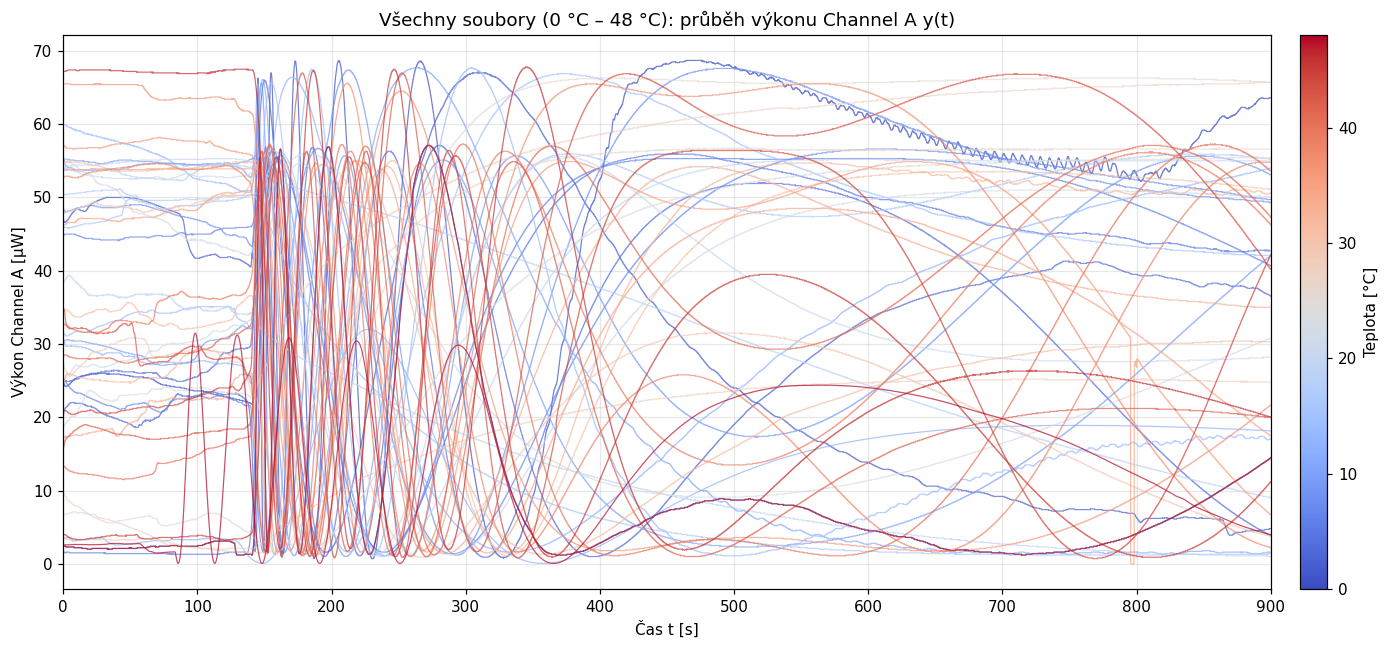

In [13]:
# --- Graf 2C: Všechny původní průběhy Channel A y(t) v jednom grafu ---
fig, ax = plt.subplots(figsize=(14, 6.0))
for temp in temps:
    d = datasets[temp]
    ax.plot(d["t"], d["y"] * 1e6, color=cmap(norm(temp)), lw=0.8, alpha=0.7)

ax.set_title("Všechny soubory (0 °C – 48 °C): průběh výkonu Channel A y(t)")
ax.set_xlabel("Čas t [s]")
ax.set_ylabel("Výkon Channel A [µW]")
ax.set_xlim(0, 900)

cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Teplota [°C]")

plt.tight_layout()
plt.show()